# COME 01 — Reproduce every segmentation number in the manuscript

Run the cells from top to bottom. Each run writes to a **new, time-stamped folder**, so no checkpoint or result is ever overwritten
(overwriting the same checkpoint file is how the earlier numbers became mixed).

| Step | Produces | Manuscript |
|---|---|---|
| 1 | split manifest, overlap and session-purity checks | Section 2.2, Table 1 |
| 2 | U-Net checkpoint and training history | Section 3.3, Figure 6 |
| 3 | single evaluation on the held-out test sessions | Table 4, Abstract, Conclusion |
| 4 | zero-shot and exploratory adaptation on AMB82-Mini frames | Section 3.4 |
| 5 | accuracy of the on-device TFLite model | Section 2.1 / 3.4 |
| 6 | Figures 6 and 7 | Figures 6, 7 |
| 7 | every number to paste into the manuscript | all |

**Two ways to run Step 2:** set `TRAIN_NEW_MODEL = False` and point `EXISTING_CKPT` to a saved checkpoint to re-evaluate it,
or `True` to train once from scratch (about 20–30 epochs).


In [1]:
# ===== CONFIGURATION — edit these paths =====
from pathlib import Path
from datetime import datetime

BASE      = Path("/home/champion/Documents/1.Books/research/Thesis/Weather/WriteUps/PHASE 2/Codes")
WASCAT    = BASE / "WASCAT" / "wascat_v1.0"                 # images/, masks/, metadata/
SPLITS    = WASCAT / "metadata" / "rf_splits_v2.csv"         # columns: id, vid, fold_v2
AMB_DIR   = BASE / "amb82_come"                              # harmonised/<id>.jpg, masks/<id>.png
AMB_META  = BASE / "reviewer3_artifacts" / "amb82_metadata.csv"   # columns: id, okta_sa
# EDGE_MODEL = BASE / "unet_edge.tflite" # on-device model (Step 5)

EDGE_MODEL = Path("/home/champion/Documents/2.Codes/.Codes/Python/AMB82-Mini/Fish-eye/quantification/model/unet_edge.tflite")
EDGE_CHANNEL_ORDER, EDGE_SCALE = "rgb", 255.0                # must match how the edge model was trained

TRAIN_NEW_MODEL = False                                       # False -> re-evaluate EXISTING_CKPT
EXISTING_CKPT   = BASE / "reviewer3_artifacts" / "unet_sessionpure_s2026.pt"
SEED = 2026

RUN = BASE / "come_runs" / datetime.now().strftime("run_%Y%m%d_%H%M%S")
RUN.mkdir(parents=True, exist_ok=False)
print("all outputs of this run go to:", RUN)


all outputs of this run go to: /home/champion/Documents/1.Books/research/Thesis/Weather/WriteUps/PHASE 2/Codes/come_runs/run_20261120_202216


In [2]:
# ===== imports (pip install numpy opencv-python pandas torch torchvision matplotlib) =====
import json, math, copy, random, hashlib
import cv2, numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", dev, "| torch", torch.__version__)


device: cuda | torch 2.12.1+cu130


## Helpers
Geometry and RBDI, oktas, metrics, strict pairing, statistics, model and training loops.


In [3]:
"""Image geometry and the Red-Blue Difference Index (RBDI).

Identical to the preprocessing used for the reported results:
square centre crop -> 480x480 -> circular sky disk (radius 480/2 - 23 px) -> RBDI normalised over the disk.
All functions are numpy/OpenCV only.
"""
import cv2
import numpy as np

HARM = 480          # harmonised side length (pixels)
DISK_MARGIN = 23    # pixels trimmed from the disk radius to exclude the lens rim
MODEL_SIZE = 320    # network input side length


def sky_disk(size=HARM, margin=DISK_MARGIN):
    """Boolean mask of the circular sky disk."""
    yy, xx = np.mgrid[0:size, 0:size]
    r = size // 2 - margin
    return ((xx - size / 2) ** 2 + (yy - size / 2) ** 2) <= r * r


def harmonise(img, msk=None, size=HARM):
    """Square centre crop and resize to `size`; returns (img, msk, disk)."""
    h, w = img.shape[:2]
    s = min(h, w)
    oy, ox = (h - s) // 2, (w - s) // 2
    img = cv2.resize(img[oy:oy + s, ox:ox + s], (size, size), interpolation=cv2.INTER_AREA)
    if msk is not None:
        msk = cv2.resize(msk[oy:oy + s, ox:ox + s], (size, size), interpolation=cv2.INTER_NEAREST)
    return img, msk, sky_disk(size)


def rbdi(img_bgr, disk):
    """Return (float image in [0,1], RBDI = (R-B) min-max normalised over the sky disk)."""
    f = img_bgr.astype(np.float32) / 255.0
    rb = f[..., 2] - f[..., 0]
    lo, hi = rb[disk].min(), rb[disk].max()
    return f, (rb - lo) / max(1e-6, hi - lo)


def model_input(img_bgr, msk=None, model_size=MODEL_SIZE):
    """Build the 4-channel (B, G, R, RBDI) network input exactly as in training.

    Returns x (4, S, S) float32, y (1, S, S) float32 or None, d (1, S, S) bool sky disk.
    """
    img, msk, disk = harmonise(img_bgr, msk)
    f, I = rbdi(img, disk)
    x480 = np.stack([f[..., 0], f[..., 1], f[..., 2], I], -1).astype(np.float32)
    x = cv2.resize(x480, (model_size, model_size), interpolation=cv2.INTER_AREA).transpose(2, 0, 1).copy()
    d = cv2.resize(disk.astype(np.uint8) * 255, (model_size, model_size), interpolation=cv2.INTER_NEAREST) > 127
    y = None
    if msk is not None:
        y = (cv2.resize(msk, (model_size, model_size), interpolation=cv2.INTER_NEAREST) > 127).astype(np.float32)[None]
    return x, y, d[None]


def solid_angle_weights(size=HARM, margin=DISK_MARGIN):
    """Per-pixel solid-angle weights for an equidistant fisheye (zero outside the disk)."""
    disk = sky_disk(size, margin)
    yy, xx = np.mgrid[0:size, 0:size]
    r = size // 2 - margin
    rr = np.sqrt((xx - size / 2) ** 2 + (yy - size / 2) ** 2)
    k = (np.pi / 2) / r
    w = k * np.sin(k * np.clip(rr, 0, r)) / np.clip(rr, 1e-6, r)
    w[~disk] = 0.0
    return w


In [4]:
"""Cloud fraction and oktas, computed INSIDE the sky disk only.

Counting the black corners outside the fisheye circle as clear sky would cap the result at
about pi/4 * 8 = 6.3 oktas, so the denominator here is always the number of sky-disk pixels.
"""
import math
import numpy as np


def cloud_fraction(cloud_mask, disk, weights=None):
    cloud = (np.asarray(cloud_mask) > 0) & disk
    if weights is None:
        return float(cloud.sum() / max(1, disk.sum()))
    return float((cloud * weights).sum() / max(1e-12, (disk * weights).sum()))


def to_okta(fraction):
    """floor(8 * fraction), capped at 8 (the convention used throughout the study)."""
    return int(min(8, math.floor(8 * fraction + 1e-9)))


In [5]:
"""Pixel-level segmentation metrics, pooled over all images and restricted to the sky disk.

`cloud` is the positive class. Clear-sky (negative-class) metrics are reported as well,
because pooled cloud-class metrics are dominated by cloud pixels on overcast data.
"""
import numpy as np


def confusion(pred, target, disk):
    p = (np.asarray(pred) > 0.5)[disk]
    t = (np.asarray(target) > 0.5)[disk]
    return dict(tp=int((p & t).sum()), fp=int((p & ~t).sum()),
                fn=int((~p & t).sum()), tn=int((~p & ~t).sum()))


def add(a, b):
    return {k: a[k] + b[k] for k in ("tp", "fp", "fn", "tn")}


def iou(c):
    return c["tp"] / max(1, c["tp"] + c["fp"] + c["fn"])


def summarise(c):
    tp, fp, fn, tn = c["tp"], c["fp"], c["fn"], c["tn"]
    n = max(1, tp + fp + fn + tn)
    cloud_iou = tp / max(1, tp + fp + fn)
    clear_iou = tn / max(1, tn + fp + fn)
    return dict(
        Accuracy=(tp + tn) / n,
        IoU=cloud_iou,
        Dice=2 * tp / max(1, 2 * tp + fp + fn),
        Precision=tp / max(1, tp + fp),
        Recall=tp / max(1, tp + fn),
        IoU_clear_sky=clear_iou,
        Recall_clear_sky=tn / max(1, tn + fp),
        Precision_clear_sky=tn / max(1, tn + fn),
        Mean_IoU=(cloud_iou + clear_iou) / 2,
        Cloud_pixel_fraction=(tp + fn) / n,
        Pixels=n,
    )


def per_image_iou(confusions):
    """IoU of each image (an image with no cloud in prediction or target scores 1.0)."""
    out = []
    for c in confusions:
        u = c["tp"] + c["fp"] + c["fn"]
        out.append(c["tp"] / u if u else 1.0)
    return out


In [6]:
# metrics namespace used by the training/evaluation helpers
import types
M = types.SimpleNamespace(confusion=confusion, add=add, iou=iou, summarise=summarise, per_image_iou=per_image_iou)


In [7]:
"""Resolve split ids to image/mask files.

The split file and the metadata do not always write ids the same way ("2" vs "0002"). Purely numeric
ids are therefore matched after removing leading zeros, but ONLY when that match is unique: if two
metadata ids reduce to the same number, loading stops with an error. Every match made this way is
written to the report, each file may be used once, and folds are checked for identical image bytes.
"""
import hashlib
from pathlib import Path
import pandas as pd


class PairingError(RuntimeError):
    pass


def _norm(iid):
    s = str(iid).strip()
    return (s.lstrip("0") or "0") if s.isdigit() else s


def load_pairs(split_csv, metadata_csv, image_dir, mask_dir, fold_col="fold_v2", id_col="id",
               require_complete=("test", "val")):
    """Return {fold: [(id, image_path, mask_path), ...]} and a report dict.

    Raises PairingError if any id in a fold listed in `require_complete` cannot be resolved, so a
    test or validation fold can never shrink silently.
    """
    splits = pd.read_csv(split_csv, dtype=str, keep_default_na=False)
    meta = pd.read_csv(metadata_csv, dtype=str, keep_default_na=False)
    if meta[id_col].duplicated().any():
        raise PairingError(f"duplicate ids in metadata: {meta.loc[meta[id_col].duplicated(), id_col].tolist()[:10]}")
    files = {r[id_col]: (r["filename"], r["mask_filename"]) for _, r in meta.iterrows()
             if r["filename"] and r["mask_filename"]}
    by_norm = {}
    for mid in files:
        by_norm.setdefault(_norm(mid), []).append(mid)
    image_dir, mask_dir = Path(image_dir), Path(mask_dir)
    folds, unresolved, ambiguous, missing_files, normalised, used = {}, [], [], [], [], {}
    for _, r in splits.iterrows():
        iid, fold = str(r[id_col]).strip(), r[fold_col]
        if iid in files:
            mid = iid
        else:
            cands = by_norm.get(_norm(iid), [])
            if len(cands) == 1:
                mid = cands[0]; normalised.append(dict(split_id=iid, metadata_id=mid, fold=fold))
            elif len(cands) > 1:
                ambiguous.append(dict(split_id=iid, candidates=cands, fold=fold)); continue
            else:
                unresolved.append(dict(split_id=iid, fold=fold)); continue
        img, msk = image_dir / files[mid][0], mask_dir / files[mid][1]
        if not (img.exists() and msk.exists()):
            missing_files.append(dict(split_id=iid, metadata_id=mid, fold=fold)); continue
        if img in used:
            raise PairingError(f"file {img.name} claimed by split ids {used[img]} and {iid}")
        used[img] = iid
        folds.setdefault(fold, []).append((iid, img, msk))
    if ambiguous:
        raise PairingError(f"{len(ambiguous)} ids match more than one metadata id, e.g. {ambiguous[:3]}")
    expected = splits[fold_col].value_counts().to_dict()
    report = dict(expected_counts=expected, counts={k: len(v) for k, v in folds.items()},
                  matched_after_removing_leading_zeros=len(normalised), normalised_matches=normalised,
                  unresolved_ids=unresolved, ids_with_missing_files=missing_files)
    lost = [x for x in unresolved + missing_files if x["fold"] in require_complete]
    if lost:
        raise PairingError(f"{len(lost)} {'/'.join(require_complete)} ids could not be loaded, e.g. {lost[:5]} "
                           "- fix the files or metadata before evaluating")
    return folds, report


def check_session_purity(split_csv, fold_col="fold_v2", vid_col="vid"):
    s = pd.read_csv(split_csv, dtype=str, keep_default_na=False)
    s = s[s[vid_col] != ""]
    n = s.groupby(vid_col)[fold_col].nunique()
    bad = n[n > 1]
    if len(bad):
        raise PairingError(f"sessions split across folds: {bad.to_dict()}")
    return s.groupby(vid_col)[fold_col].first().to_dict()


def sha1(path, chunk=1 << 20):
    h = hashlib.sha1()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


def check_no_overlap(folds, eval_fold="test"):
    """Raise if any evaluation image is byte-identical to an image in another fold."""
    hashes = {fold: {sha1(p[1]): p[0] for p in items} for fold, items in folds.items()}
    clashes = []
    for fold, h in hashes.items():
        if fold == eval_fold:
            continue
        for digest, iid in hashes.get(eval_fold, {}).items():
            if digest in h:
                clashes.append((iid, fold, h[digest]))
    if clashes:
        raise PairingError(f"{len(clashes)} {eval_fold} images also appear in other folds, e.g. {clashes[:5]}")
    return True


def write_manifest(folds, path):
    rows = [dict(fold=f, id=i, image=p.name, mask=m.name, sha1=sha1(p)) for f, items in folds.items()
            for i, p, m in items]
    pd.DataFrame(rows).sort_values(["fold", "id"]).to_csv(path, index=False)


In [8]:
"""Paired bootstrap for the adaptation gain.

The zero-shot and adapted models are evaluated on the SAME held-out frames, so frames are
resampled jointly and the gain is computed on pooled IoU, the quantity reported in the paper.
"""
import numpy as np


def paired_bootstrap_pooled_iou(conf_a, conf_b, n=5000, seed=0, alpha=0.05):
    """95% CI for pooled IoU(a) - pooled IoU(b); conf_* are lists of per-frame confusion dicts."""
    assert len(conf_a) == len(conf_b), "paired bootstrap needs the same frames for both models"
    A = np.array([[c["tp"], c["fp"], c["fn"]] for c in conf_a], dtype=np.float64)
    B = np.array([[c["tp"], c["fp"], c["fn"]] for c in conf_b], dtype=np.float64)
    rng = np.random.default_rng(seed)
    gains = np.empty(n)
    for k in range(n):
        idx = rng.integers(0, len(A), len(A))
        a, b = A[idx].sum(0), B[idx].sum(0)
        gains[k] = a[0] / max(1, a.sum()) - b[0] / max(1, b.sum())
    point = iou(_sum(conf_a)) - iou(_sum(conf_b))
    lo, hi = np.percentile(gains, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return dict(gain=float(point), ci_low=float(lo), ci_high=float(hi), n_resamples=n, seed=seed)


def _sum(cs):
    out = dict(tp=0, fp=0, fn=0, tn=0)
    for c in cs:
        for k in out:
            out[k] += c[k]
    return out


In [9]:
"""U-Net used for all reported segmentation results.

Input: 4 channels (B, G, R, RBDI) at 320x320. Base width 32 (32-64-128-256 encoder, 512 bottleneck),
two 3x3 conv + BatchNorm + ReLU per block, transposed-conv upsampling. About 7.77 M parameters.
"""
import torch
import torch.nn as nn


class DoubleConv(nn.Module):
    def __init__(self, ci, co):
        super().__init__()
        self.b = nn.Sequential(nn.Conv2d(ci, co, 3, padding=1), nn.BatchNorm2d(co), nn.ReLU(True),
                               nn.Conv2d(co, co, 3, padding=1), nn.BatchNorm2d(co), nn.ReLU(True))

    def forward(self, x):
        return self.b(x)


class UNet(nn.Module):
    def __init__(self, in_ch=4, c=32):
        super().__init__()
        self.p = nn.MaxPool2d(2)
        self.e1, self.e2 = DoubleConv(in_ch, c), DoubleConv(c, 2 * c)
        self.e3, self.e4 = DoubleConv(2 * c, 4 * c), DoubleConv(4 * c, 8 * c)
        self.b = DoubleConv(8 * c, 16 * c)
        self.u3, self.d3 = nn.ConvTranspose2d(16 * c, 8 * c, 2, 2), DoubleConv(16 * c, 8 * c)
        self.u2, self.d2 = nn.ConvTranspose2d(8 * c, 4 * c, 2, 2), DoubleConv(8 * c, 4 * c)
        self.u1, self.d1 = nn.ConvTranspose2d(4 * c, 2 * c, 2, 2), DoubleConv(4 * c, 2 * c)
        self.u0, self.d0 = nn.ConvTranspose2d(2 * c, c, 2, 2), DoubleConv(2 * c, c)
        self.out = nn.Conv2d(c, 1, 1)

    def forward(self, x):
        x1 = self.e1(x); x2 = self.e2(self.p(x1)); x3 = self.e3(self.p(x2)); x4 = self.e4(self.p(x3))
        y = self.d3(torch.cat([self.u3(self.b(self.p(x4))), x4], 1))
        y = self.d2(torch.cat([self.u2(y), x3], 1))
        y = self.d1(torch.cat([self.u1(y), x2], 1))
        return self.out(self.d0(torch.cat([self.u0(y), x1], 1)))


In [10]:
"""Dataset, loss, training and evaluation loops (PyTorch). Hyper-parameters match the manuscript."""
import random
import cv2
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset



def seed_everything(seed=2026, deterministic=True):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    if deterministic:  # GPU kernels are otherwise non-deterministic: identical seeds give slightly different runs
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


class SkyPairs(Dataset):
    """items: list of (id, image_path, mask_path)."""
    def __init__(self, items):
        self.items = list(items)

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        _, ip, mp = self.items[i]
        img, msk = cv2.imread(str(ip)), cv2.imread(str(mp), 0)
        if img is None or msk is None:
            raise FileNotFoundError(f"unreadable pair: {ip} / {mp}")
        x, y, d = model_input(img, msk)
        return torch.from_numpy(x), torch.from_numpy(y), torch.from_numpy(d)


def soft_dice(logits, y):
    p = torch.sigmoid(logits); dims = (1, 2, 3)
    return ((2 * (p * y).sum(dims) + 1e-6) / (p.sum(dims) + y.sum(dims) + 1e-6)).mean()


def loss_fn(logits, y):
    """Composite loss: binary cross-entropy + (1 - soft Dice)."""
    return nn.functional.binary_cross_entropy_with_logits(logits, y) + (1 - soft_dice(logits, y))


@torch.no_grad()
def predict_confusions(model, items, device, bs=8):
    """Per-image confusion counts inside the sky disk (threshold 0.5)."""
    model.eval()
    out = []
    for x, y, d in DataLoader(SkyPairs(items), bs, shuffle=False):
        p = (model(x.to(device)).sigmoid() > 0.5).cpu().numpy()
        for pi, yi, di in zip(p, y.numpy(), d.numpy()):
            out.append(M.confusion(pi, yi, di))
    return out


def evaluate(model, items, device):
    """Pooled metrics, per-image IoU and per-image confusions for `items`."""
    conf = predict_confusions(model, items, device)
    total = dict(tp=0, fp=0, fn=0, tn=0)
    for c in conf:
        total = M.add(total, c)
    return M.summarise(total), M.per_image_iou(conf), conf


def train_from_scratch(model, train_items, val_items, device, lr=1e-4, bs=8, max_epochs=110,
                       patience=15, min_delta=1e-4, seed=2026, log=print):
    """Adam, BCE + Dice, early stopping on validation IoU; returns (best_state, history)."""
    g = torch.Generator(); g.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr)
    tr = DataLoader(SkyPairs(train_items), bs, shuffle=True, generator=g)
    hist = dict(epoch=[], tr_loss=[], va_iou=[])
    best, bad, best_state = -1.0, 0, None
    for ep in range(max_epochs):
        model.train(); tl = 0.0
        for x, y, _ in tr:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step(); tl += loss.item() * len(x)
        va_metrics, _, _ = evaluate(model, val_items, device)
        hist["epoch"].append(ep + 1); hist["tr_loss"].append(tl / len(train_items)); hist["va_iou"].append(va_metrics["IoU"])
        log(f"epoch {ep + 1:3d}  train loss {hist['tr_loss'][-1]:.4f}  val IoU {va_metrics['IoU']:.4f}")
        if va_metrics["IoU"] > best + min_delta:
            best, bad = va_metrics["IoU"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                log(f"early stop after epoch {ep + 1}; best val IoU {best:.4f}")
                break
    if best_state is None:
        raise RuntimeError("validation IoU never improved - check data loading")
    return best_state, hist


def fine_tune(model, items, device, lr=1e-5, bs=4, epochs=15, seed=2026):
    """Fixed-length end-to-end fine-tuning; the final-epoch weights are kept (no checkpoint selection)."""
    g = torch.Generator(); g.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr)
    dl = DataLoader(SkyPairs(items), bs, shuffle=True, generator=g)
    for _ in range(epochs):
        model.train()
        for x, y, _ in dl:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
    return model


In [11]:
# Self-check: runs in seconds without any data. Every line must print OK.
import math, tempfile
def close(a, b, tol): assert math.isclose(a, b, abs_tol=tol), (a, b)

x, y, d = model_input(np.random.default_rng(0).integers(0, 256, (1280, 1920, 3), dtype=np.uint8),
                      np.zeros((1280, 1920), np.uint8))
assert x.shape == (4, 320, 320) and 0 <= x.min() and x.max() <= 1; print("OK model input: 4 x 320 x 320")

s = summarise(dict(tp=824881, fp=54406, fn=45727, tn=74986))      # confusion implied by Table 4
close(s["IoU"], 0.8917, 2e-4); close(s["IoU_clear_sky"], 0.4282, 5e-4); close(s["Recall_clear_sky"], 0.5795, 5e-4)
print("OK metrics reproduce Table 4 and the reviewer's clear-sky figures")

disk = sky_disk(); assert to_okta(cloud_fraction(disk, disk)) == 8 and to_okta(disk.sum() / disk.size) <= 6
print("OK oktas use the sky-disk denominator (an overcast sky gives 8, not 6)")

r = paired_bootstrap_pooled_iou([dict(tp=9, fp=1, fn=0, tn=0)] * 30, [dict(tp=7, fp=2, fn=1, tn=0)] * 30, n=200)
close(r["gain"], 0.9 - 0.7, 1e-9); print("OK paired bootstrap")

tmp = Path(tempfile.mkdtemp()); (tmp / "images").mkdir(); (tmp / "masks").mkdir()
cv2.imwrite(str(tmp / "images/0005.jpg"), np.zeros((8, 8, 3), np.uint8)); cv2.imwrite(str(tmp / "masks/0005.png"), np.zeros((8, 8), np.uint8))
pd.DataFrame([dict(id="0005", filename="0005.jpg", mask_filename="0005.png")]).to_csv(tmp / "meta.csv", index=False)
pd.DataFrame([dict(id="5", vid="", fold_v2="test")]).to_csv(tmp / "s.csv", index=False)
f_, rep = load_pairs(tmp / "s.csv", tmp / "meta.csv", tmp / "images", tmp / "masks")
assert len(f_["test"]) == 1 and rep["matched_after_removing_leading_zeros"] == 1
print("OK split id '5' matches metadata id '0005' (unique match); ambiguous matches would stop with an error")


OK model input: 4 x 320 x 320
OK metrics reproduce Table 4 and the reviewer's clear-sky figures
OK oktas use the sky-disk denominator (an overcast sky gives 8, not 6)
OK paired bootstrap
OK split id '5' matches metadata id '0005' (unique match); ambiguous matches would stop with an error


## Step 1 — Load the session-disjoint split and check it


In [12]:
seed_everything(SEED)
session_fold = check_session_purity(SPLITS)                 # raises if a video session spans two folds
folds, report = load_pairs(SPLITS, WASCAT / "metadata" / "master_metadata.csv", WASCAT / "images", WASCAT / "masks")
check_no_overlap(folds, "test"); check_no_overlap(folds, "val")   # raises if a test/val image also appears elsewhere
write_manifest(folds, RUN / "split_manifest.csv")
report["session_fold"] = session_fold
json.dump(report, open(RUN / "pairing_report.json", "w"), indent=2)
vid_of = pd.read_csv(SPLITS, dtype=str, keep_default_na=False).set_index("id")["vid"].to_dict()
summary = pd.DataFrame({"in split file": pd.Series(report["expected_counts"]), "loaded": pd.Series(report["counts"])}).fillna(0).astype(int)
summary["sessions loaded"] = [", ".join(sorted({vid_of.get(i) for i, _, _ in folds.get(f, []) if vid_of.get(i)}, key=lambda v: int(v[3:]) if v[3:].isdigit() else 99)) for f in summary.index]
summary["single shots"] = [sum(1 for i, _, _ in folds.get(f, []) if not vid_of.get(i)) for f in summary.index]
print(f"ids matched after removing leading zeros: {report['matched_after_removing_leading_zeros']} (all unique)")
print("train ids that could not be loaded:", [x["split_id"] for x in report["unresolved_ids"] + report["ids_with_missing_files"]])
summary   # expected: train 657 (655 loadable) | val 108 (vid9, vid10 + 8 single shots) | test 80 (vid1, vid11)


ids matched after removing leading zeros: 397 (all unique)
train ids that could not be loaded: ['5', '32']


,in split file,loaded,sessions loaded,single shots
train,657,655,"vid2, vid3, vid4, vid5, vid6, vid8",43
val,108,108,"vid9, vid10",8
test,80,80,"vid1, vid11",0


## Step 2 — Train once from scratch, or load an existing checkpoint


In [13]:
model = UNet().to(dev)
if TRAIN_NEW_MODEL:
    best, hist = train_from_scratch(model, folds["train"], folds["val"], dev, seed=SEED)
    torch.save(best, RUN / "unet_sessionpure.pt")
    pd.DataFrame(hist).to_csv(RUN / "training_history.csv", index=False)
else:
    best = torch.load(EXISTING_CKPT, map_location=dev)
    torch.save(best, RUN / "unet_sessionpure.pt")             # keep a copy with this run's results
    hist = None
    print("loaded", EXISTING_CKPT, "- no training history (Figure 6 needs the history CSV of the run that made it)")
model.load_state_dict(best); model.to(dev)


loaded /home/champion/Documents/1.Books/research/Thesis/Weather/WriteUps/PHASE 2/Codes/reviewer3_artifacts/unet_sessionpure_s2026.pt - no training history (Figure 6 needs the history CSV of the run that made it)


UNet(
  (p): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (e1): DoubleConv(
    (b): Sequential(
      (0): Conv2d(4, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (e2): DoubleConv(
    (b): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU

## Step 3 — ONE evaluation on the held-out test sessions (Table 4)


In [14]:
test_metrics, test_per_image, test_conf = evaluate(model, folds["test"], dev)
vid = pd.read_csv(SPLITS, dtype=str, keep_default_na=False).set_index("id")["vid"].to_dict()
by_s, n_s = {}, {}
for (iid, _, _), c in zip(folds["test"], test_conf):
    s = vid.get(iid) or "single_shot"; by_s[s] = add(by_s.get(s, dict(tp=0, fp=0, fn=0, tn=0)), c); n_s[s] = n_s.get(s, 0) + 1
smart = dict(test=test_metrics,
             test_per_session={s: dict(summarise(c), n_images=n_s[s]) for s, c in by_s.items()},
             per_image_iou=dict(zip([i for i, _, _ in folds["test"]], test_per_image)),
             fold_sizes=report["counts"], seed=SEED)
if hist:
    k = int(np.argmax(hist["va_iou"])); smart.update(best_val_iou=hist["va_iou"][k], best_epoch=hist["epoch"][k], epochs_run=len(hist["epoch"]))
json.dump(smart, open(RUN / "results_smartphone.json", "w"), indent=2)
pd.DataFrame(smart["test_per_session"]).T.round(4)


,Accuracy,IoU,Dice,Precision,Recall,IoU_clear_sky,Recall_clear_sky,Precision_clear_sky,Mean_IoU,Cloud_pixel_fraction,Pixels,n_images
vid11,0.9976,0.9976,0.9988,0.9980,0.9996,0.5597,0.6071,0.8776,0.7787,0.9950,3220819.0,49.0
vid1,0.7410,0.6752,0.8061,0.8135,0.7989,0.4390,0.6215,0.5992,0.5571,0.6739,2037661.0,31.0


## Step 4 — Cross-instrument: zero-shot on all 150 AMB82-Mini frames, then exploratory adaptation


In [16]:
meta = pd.read_csv(AMB_META).sort_values("id").reset_index(drop=True)
amb = {r.id: (r.id, AMB_DIR / "harmonised" / f"{r.id}.jpg", AMB_DIR / "masks" / f"{r.id}.png") for r in meta.itertuples()}
missing = [i for i, (_, p, m) in amb.items() if not (p.exists() and m.exists())]
assert not missing, f"{len(missing)} AMB82 pairs missing, e.g. {missing[:5]}"

zero_all, zero_all_per, _ = evaluate(model, list(amb.values()), dev)

half = meta.groupby("okta_sa", group_keys=False).sample(frac=0.5, random_state=SEED)   # okta-stratified 50/50
split = pd.DataFrame(dict(id=meta.id, side=["adapt" if i in set(half.id) else "heldout" for i in meta.id]))
split.to_csv(RUN / "adaptation_split.csv", index=False)
adapt = [amb[i] for i in split.loc[split.side == "adapt", "id"]]
held  = [amb[i] for i in split.loc[split.side == "heldout", "id"]]

zero_held, _, zero_conf = evaluate(model, held, dev)                     # zero-shot on the SAME held-out frames
tuned = fine_tune(copy.deepcopy(model), adapt, dev, epochs=15, seed=SEED)  # 15 epochs, Adam 1e-5, batch 4, final weights
adapted, _, adapted_conf = evaluate(tuned, held, dev)
ci = paired_bootstrap_pooled_iou(adapted_conf, zero_conf)

cross = dict(zero_shot_all=dict(zero_all, n_images=len(amb)), zero_shot_per_image_iou=dict(zip(amb.keys(), zero_all_per)),
             zero_shot_heldout=dict(zero_held, n_images=len(held)), adapted_heldout=dict(adapted, n_images=len(held)),
             adaptation=dict(n_adapt=len(adapt), epochs=15, lr=1e-5, batch_size=4,
                             split="okta-stratified 50/50, not session-disjoint", gain_pooled_iou=ci), seed=SEED)
json.dump(cross, open(RUN / "results_cross_instrument.json", "w"), indent=2)
print(f"zero-shot, all {len(amb)} frames: IoU {zero_all['IoU']:.4f}  Dice {zero_all['Dice']:.4f}")
print(f"held-out {len(held)} frames: zero-shot {zero_held['IoU']:.4f} -> adapted {adapted['IoU']:.4f}  "
      f"(gain {ci['gain']:+.4f}, 95% CI {ci['ci_low']:+.4f} to {ci['ci_high']:+.4f})")


zero-shot, all 150 frames: IoU 0.7910  Dice 0.8833
held-out 75 frames: zero-shot 0.7850 -> adapted 0.9490  (gain +0.1640, 95% CI +0.1207 to +0.2122)


## Step 5 — Accuracy of the on-device model (unet_edge.tflite) on the same frames
Needs `pip install ai-edge-litert` (or tensorflow). Skipped if the file is not found.


In [24]:
%pip install ai-edge-litert

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.0/21.0 MB 2.9 MB/s  0:00:07 eta 0:00:010:01:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [ai-edge-litert] 1/2 [ai-edge-litert]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [25]:
from ai_edge_litert.interpreter import Interpreter
it = Interpreter(model_path="/home/champion/Documents/2.Codes/.Codes/Python/AMB82-Mini/Fish-eye/quantification/model/unet_edge.tflite")
it.allocate_tensors(); print(it.get_input_details()[0]["shape"])

[  1 256 256   3]


/tmp/ipykernel_85992/2493055593.py:1: FutureWarning: ai-edge-litert support for Python 3.10 is deprecated and will be removed in the next release, following Python 3.10's upstream end-of-life (https://peps.python.org/pep-0619/). Please upgrade to Python 3.11 or newer.
  from ai_edge_litert.interpreter import Interpreter
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [20]:
def load_tflite(path):
    try:
        from ai_edge_litert.interpreter import Interpreter
    except ImportError:
        try:
            from tflite_runtime.interpreter import Interpreter
        except ImportError:
            from tensorflow.lite.python.interpreter import Interpreter
    it = Interpreter(model_path=str(path)); it.allocate_tensors(); return it

def edge_confusion(it, img_bgr, msk):
    inp, out = it.get_input_details()[0], it.get_output_details()[0]; S = int(inp["shape"][1])
    img, msk, disk = harmonise(img_bgr, msk)
    x = cv2.resize(img, (S, S), interpolation=cv2.INTER_AREA)
    if EDGE_CHANNEL_ORDER == "bgr": x = cv2.cvtColor(x, cv2.COLOR_BGR2RGB)
    it.set_tensor(inp["index"], (x.astype(np.float32) / EDGE_SCALE)[None]); it.invoke()
    prob = it.get_tensor(out["index"])[0, ..., 0]
    d = cv2.resize(disk.astype(np.uint8) * 255, (S, S), interpolation=cv2.INTER_NEAREST) > 127
    return confusion(prob > 0.5, cv2.resize(msk, (S, S), interpolation=cv2.INTER_NEAREST) > 127, d)

edge = {}
if EDGE_MODEL.exists():
    it = load_tflite(EDGE_MODEL)
    print("edge model input:", it.get_input_details()[0]["shape"], it.get_input_details()[0]["dtype"])
    for name, items in [("smartphone_test", folds["test"]), ("amb82_all", list(amb.values()))]:
        tot = dict(tp=0, fp=0, fn=0, tn=0)
        for _, p, m in items: tot = add(tot, edge_confusion(it, cv2.imread(str(p)), cv2.imread(str(m), 0)))
        edge[name] = dict(summarise(tot), n_images=len(items))
        print(f"{name}: IoU {edge[name]['IoU']:.4f}  Dice {edge[name]['Dice']:.4f}")
    json.dump(dict(model=EDGE_MODEL.name, channel_order=EDGE_CHANNEL_ORDER, scale=EDGE_SCALE, **edge),
              open(RUN / "results_edge_tflite.json", "w"), indent=2)
else:
    print("edge model not found - Step 5 skipped:", EDGE_MODEL)


edge model input: [  1 256 256   3] <class 'numpy.float32'>
smartphone_test: IoU 0.5292  Dice 0.6921
amb82_all: IoU 0.4893  Dice 0.6571


## Step 6 — Figures 6 and 7


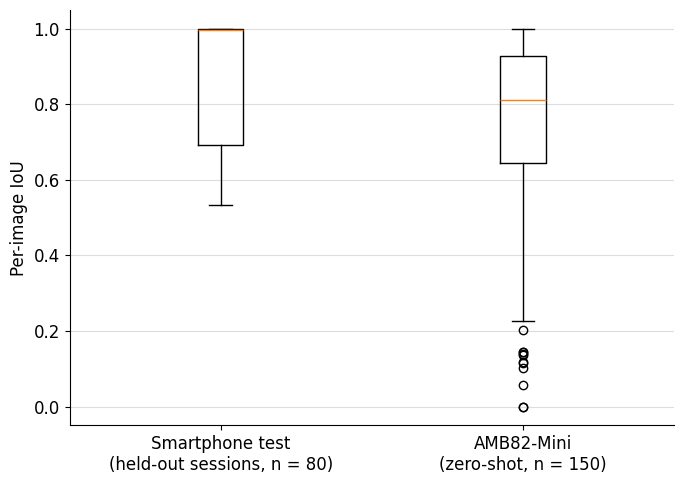

In [18]:
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
if hist:
    h = pd.DataFrame(hist)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
    a1.plot(h.epoch, h.tr_loss, lw=2, color="#1f3b73"); a1.set_ylabel("Training loss\n(BCE + Dice)"); a1.set_title("(a)", loc="left")
    a2.plot(h.epoch, h.va_iou, lw=2, marker="o", ms=4, color="#1f3b73")
    a2.plot(smart["best_epoch"], smart["best_val_iou"], "o", ms=9, color="#c2410c", mec="white")
    a2.axvline(h.epoch.iloc[-1], ls="--", color="#555", lw=1)
    a2.set_ylabel("Validation IoU"); a2.set_xlabel("Epoch"); a2.set_title("(b)", loc="left")
    for ax in (a1, a2): ax.grid(axis="y", color="#ddd")
    fig.tight_layout(); fig.savefig(RUN / "figure6_learning_curves.png", dpi=300); plt.show()

phone, ambv = list(smart["per_image_iou"].values()), list(cross["zero_shot_per_image_iou"].values())
fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot([phone, ambv]); ax.set_xticks([1, 2], [f"Smartphone test\n(held-out sessions, n = {len(phone)})", f"AMB82-Mini\n(zero-shot, n = {len(ambv)})"])
ax.set_ylabel("Per-image IoU"); ax.grid(axis="y", color="#ddd")
fig.tight_layout(); fig.savefig(RUN / "figure7_cross_instrument.png", dpi=300); plt.show()


## Step 7 — Numbers for the manuscript
Send the whole run folder (or at least the JSON and CSV files) so the manuscript and response letter can be updated from one run.


In [19]:
t, z, zh, ad, g = smart["test"], cross["zero_shot_all"], cross["zero_shot_heldout"], cross["adapted_heldout"], cross["adaptation"]["gain_pooled_iou"]
pct = lambda v: f"{100 * v:.2f}%"
print(f"""RUN FOLDER: {RUN}
TABLE 4 (test, {sum(n_s.values())} images): Accuracy {t['Accuracy']:.4f} | Dice {t['Dice']:.4f} | IoU cloud {t['IoU']:.4f} | IoU clear sky {t['IoU_clear_sky']:.4f}
   Mean IoU {t['Mean_IoU']:.4f} | Precision {t['Precision']:.4f} | Recall {t['Recall']:.4f} | Clear-sky recall {t['Recall_clear_sky']:.4f} | cloud pixels {pct(t['Cloud_pixel_fraction'])}
PER SESSION: """ + "; ".join(f"{s} (n={v['n_images']}): IoU {v['IoU']:.4f}, clear-sky IoU {v['IoU_clear_sky']:.4f}" for s, v in smart["test_per_session"].items()) + f"""
FOLDS: {smart['fold_sizes']}""" + (f"""
FIGURE 6: best val IoU {smart['best_val_iou']:.4f} at epoch {smart['best_epoch']}; training stopped after epoch {smart['epochs_run']}""" if hist else "") + f"""
SECTION 3.4: zero-shot IoU {pct(z['IoU'])} (Dice {pct(z['Dice'])}) on {z['n_images']} frames;
   held-out {zh['n_images']}: zero-shot {pct(zh['IoU'])} -> adapted {pct(ad['IoU'])} (Dice {pct(ad['Dice'])}); gain CI {100*g['ci_low']:+.2f} to {100*g['ci_high']:+.2f} points""")
for k, v in edge.items(): print(f"EDGE TFLITE {k}: IoU {pct(v['IoU'])}, Dice {pct(v['Dice'])}")


RUN FOLDER: /home/champion/Documents/1.Books/research/Thesis/Weather/WriteUps/PHASE 2/Codes/come_runs/run_20261120_202216
TABLE 4 (test, 80 images): Accuracy 0.8982 | Dice 0.9414 | IoU cloud 0.8893 | IoU clear sky 0.4412
   Mean IoU 0.6652 | Precision 0.9434 | Recall 0.9394 | Clear-sky recall 0.6211 | cloud pixels 87.06%
PER SESSION: vid11 (n=49): IoU 0.9976, clear-sky IoU 0.5597; vid1 (n=31): IoU 0.6752, clear-sky IoU 0.4390
FOLDS: {'train': 655, 'val': 108, 'test': 80}
SECTION 3.4: zero-shot IoU 79.10% (Dice 88.33%) on 150 frames;
   held-out 75: zero-shot 78.50% -> adapted 94.90% (Dice 97.38%); gain CI +12.07 to +21.22 points
EDGE TFLITE smartphone_test: IoU 52.97%, Dice 69.25%
EDGE TFLITE amb82_all: IoU 53.44%, Dice 69.65%
